In [7]:
!pip install -q kaggle


In [8]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")


Enter your Kaggle API token: ··········


In [9]:
!kaggle datasets list --max-size 5


ref                                                               title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
georgymamarin/kaggriculture-episodes                              Kaggriculture Episodes                              10972066754  2026-09-05 09:07:04.657000          17434         60                1  
hubertsidorowicz/steam-games-dataset-daily-updates                Steam Games Dataset All Games 136K+                   185613476  2026-09-05 12:23:53.053000           1337         28                1  
ashok205/kaggriculture-top10-replay-archive                       Kaggriculture Daily Top-10 Replay Archive            1732702677  2026-09-04 23:26:34.620000           1175          0     

In [10]:
!kaggle datasets download -d hamaskhan/flowers-classification-dataset
!unzip -q flowers-classification-dataset.zip -d dataset


!ls dataset


Dataset URL: https://www.kaggle.com/datasets/hamaskhan/flowers-classification-dataset
License(s): unknown
100% 1.01k/1.01k [00:00<00:00, 2.84MB/s]

flowers_dataset.csv


In [11]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print(root, "->", len(files), "files")


/content/dataset -> 1 files


In [15]:
import os

files = os.listdir("/content/dataset")
print(files)


['flowers_dataset.csv']


In [16]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [19]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print("ROOT:", root)
    print("DIRS:", dirs)
    print("FILES:", files)


!ls -lah /content/dataset


ROOT: /content/dataset
DIRS: []
FILES: ['flowers_dataset.csv']
total 16K
drwxr-xr-x 2 root root 4.0K Sep  5 17:24 .
drwxr-xr-x 1 root root 4.0K Sep  5 17:24 ..
-rw-r--r-- 1 root root 4.6K Nov  2  2023 flowers_dataset.csv


In [20]:
import pandas as pd

csv_path = "/content/dataset/flowers_dataset.csv"

df = pd.read_csv(csv_path)

print(df.head())
print("\nColumns:")
print(df.columns)

print("\nShape:", df.shape)

print(df.iloc[0])


   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Columns:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

Shape: (150, 5)
sepal_length            5.1
sepal_width             3.5
petal_length            1.4
petal_width             0.2
species         Iris-setosa
Name: 0, dtype: object


In [21]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load the CSV dataset
df = pd.read_csv("/content/dataset/flowers_dataset.csv")

# Display the first few rows
print(df.head())

# Separate features and labels
X = df[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
].values

y = df["species"].values

# Convert class names into numbers
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Check the classes
class_names = label_encoder.classes_

print("Classes:", class_names)
print("Number of classes:", len(class_names))



   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Number of classes: 3


In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=123,
    stratify=y
)


In [23]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=123,
    stratify=y_temp
)


In [24]:
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 105
Validation samples: 22
Testing samples: 23


In [25]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)


In [26]:
BATCH_SIZE = 32

train_ds = train_ds.shuffle(
    buffer_size=len(X_train),
    seed=123
).batch(BATCH_SIZE)

val_ds = val_ds.batch(BATCH_SIZE)

test_ds = test_ds.batch(BATCH_SIZE)


In [28]:
class_names = label_encoder.classes_

print("Classes:")
print(class_names)

print("Number of classes:", len(class_names))


Classes:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Number of classes: 3


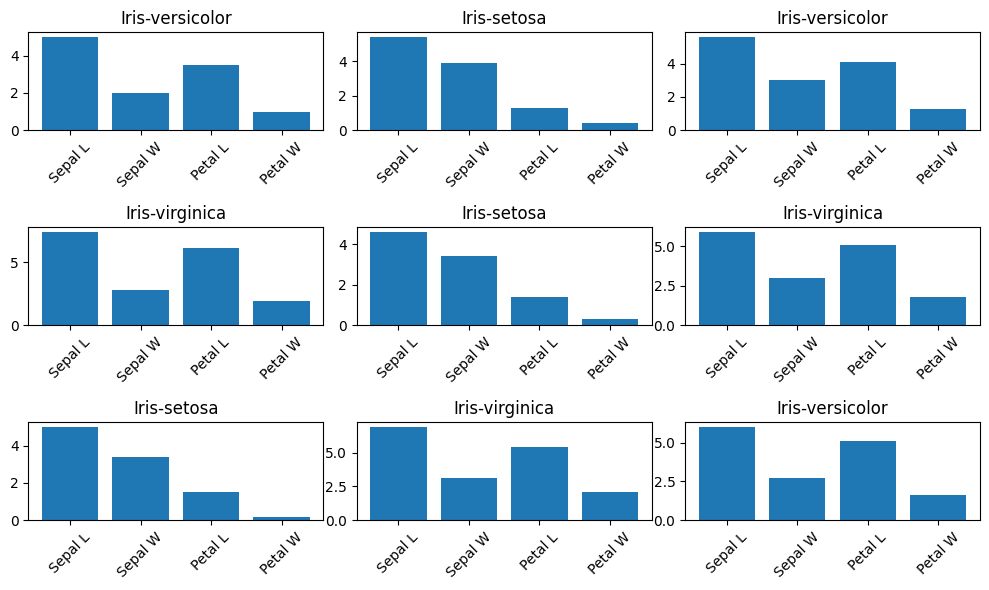

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.bar(
        ["Sepal L", "Sepal W", "Petal L", "Petal W"],
        X_train[i]
    )

    plt.title(class_names[y_train[i]])
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [30]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


In [31]:
# ==========================================
# Task B — Neural Network Classification
# ==========================================

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf


# ==========================================
# Step B1 — Define input and classes
# ==========================================

input_shape = (4,)
num_classes = len(class_names)

print("Input shape:", input_shape)
print("Number of classes:", num_classes)
print("Classes:", class_names)


# ==========================================
# Step B2 — Create the model
# ==========================================

inputs = keras.Input(shape=input_shape)

x = layers.Dense(
    16,
    activation="relu"
)(inputs)

x = layers.Dense(
    8,
    activation="relu"
)(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs
)


# ==========================================
# Step B3 — Display model architecture
# ==========================================

model.summary()


# ==========================================
# Step B4 — Compile the model
# ==========================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ==========================================
# Step B5 — Train the model
# ==========================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50
)


# ==========================================
# Step B6 — Evaluate the model
# ==========================================

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Input shape: (4,)
Number of classes: 3
Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 518ms/step - accuracy: 0.2667 - loss: 1.5604 - val_accuracy: 0.3636 - val_loss: 1.2805
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3048 - loss: 1.3888 - val_accuracy: 0.3636 - val_loss: 1.2424
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3429 - loss: 1.3784 - val_accuracy: 0.3636 - val_loss: 1.2106
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2571 - loss: 1.4084 - val_accuracy: 0.3636 - val_loss: 1.1822
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2857 - loss: 1.3919 - val_accuracy: 0.3636 - val_loss: 1.1571
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3429 - loss: 1.2894 - val_accuracy: 0.4091 - val_loss: 1.1361
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3619 - loss: 1.2711 - val_accuracy: 0.4091 - val_loss: 1.1178
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4000 - loss: 1.2131 - val_accuracy: 0.4091 - val_loss: 1.1026
Epoch

Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Number of classes: 3

Dataset sizes:
Training: 105
Validation: 22
Testing: 23


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 412ms/step - accuracy: 0.3333 - loss: 1.1847 - val_accuracy: 0.5000 - val_loss: 1.1257
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4000 - loss: 1.1278 - val_accuracy: 0.5000 - val_loss: 1.0945
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3905 - loss: 1.1036 - val_accuracy: 0.5000 - val_loss: 1.0718
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3905 - loss: 1.0671 - val_accuracy: 0.5000 - val_loss: 1.0515
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3429 - loss: 1.0824 - val_accuracy: 0.5000 - val_loss: 1.0303
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4095 - loss: 1.0230 - val_accuracy: 0.5000 - val_loss: 1.0083
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4381 - loss: 1.0241 - val_accuracy: 0.5000 - val_loss: 0.9877
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4190 - loss: 0.9981 - val_accuracy: 0.5000 - val_loss: 0.9698
Epoch 

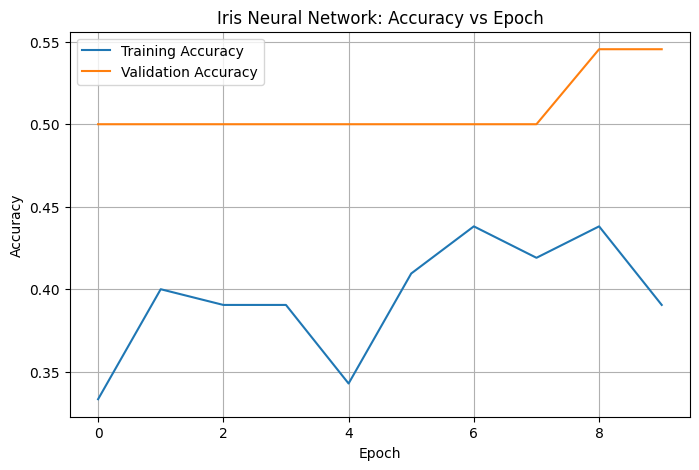

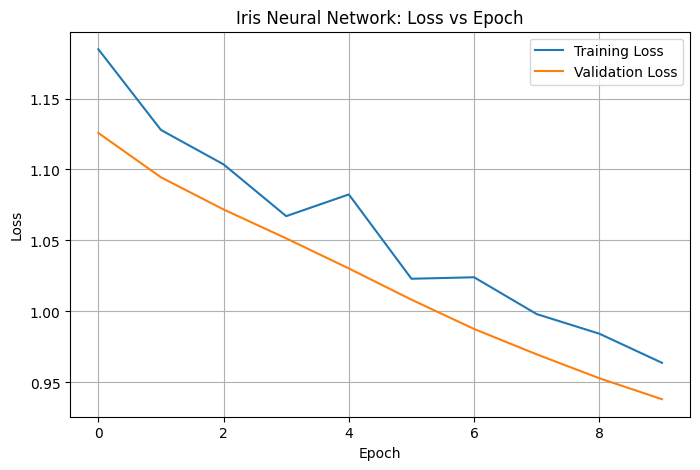

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.5652 - loss: 0.9342

Test Loss: 0.9341546893119812
Test Accuracy: 0.5652173757553101

FINAL RESULTS
Training Accuracy: 0.3905
Validation Accuracy: 0.5455
Training Loss: 0.9638
Validation Loss: 0.9382
Test Accuracy: 0.5652

Results Table:
             Metric   Result
  Training Accuracy 0.390476
Validation Accuracy 0.545455
      Training Loss 0.963828
    Validation Loss 0.938176
      Test Accuracy 0.565217

Model saved as: iris_neural_network.keras

TASK C COMPLETED
Training Accuracy   : 0.3905
Validation Accuracy : 0.5455
Training Loss       : 0.9638
Validation Loss     : 0.9382
Test Accuracy       : 0.5652


In [32]:
# ============================================================
# TASK C — MODEL TRAINING AND PERFORMANCE EVALUATION
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


# ============================================================
# STEP C0 — LOAD AND PREPARE THE DATA
# ============================================================

df = pd.read_csv("/content/dataset/flowers_dataset.csv")

# Input features
X = df[
    [
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
].values

# Target labels
y = df["species"].values


# Convert species names to numerical labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Class names
class_names = label_encoder.classes_

print("Classes:", class_names)
print("Number of classes:", len(class_names))


# ============================================================
# STEP C0.1 — SPLIT DATA
# 70% Training
# 15% Validation
# 15% Testing
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=123,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=123,
    stratify=y_temp
)

print("\nDataset sizes:")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


# ============================================================
# STEP C0.2 — CREATE TENSORFLOW DATASETS
# ============================================================

BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

# Shuffle and batch training dataset
train_ds = train_ds.shuffle(
    buffer_size=len(X_train),
    seed=123
).batch(BATCH_SIZE)

# Batch validation and test datasets
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)


# ============================================================
# STEP C0.3 — PREFETCH DATA
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


# ============================================================
# STEP C0.4 — CREATE THE MODEL
# ============================================================

num_classes = len(class_names)

inputs = keras.Input(shape=(4,))

x = layers.Dense(
    16,
    activation="relu"
)(inputs)

x = layers.Dense(
    8,
    activation="relu"
)(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs
)


# ============================================================
# STEP C0.5 — DISPLAY MODEL
# ============================================================

model.summary()


# ============================================================
# STEP C0.6 — COMPILE MODEL
# ============================================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# STEP C1 — TRAIN THE MODEL
# ============================================================

EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


# ============================================================
# STEP C2 — GET TRAINING ACCURACY
# ============================================================

training_accuracy = history.history["accuracy"]

print("\nTraining Accuracy:")
print(training_accuracy)

print(
    "Final Training Accuracy:",
    training_accuracy[-1]
)


# ============================================================
# STEP C3 — GET VALIDATION ACCURACY
# ============================================================

validation_accuracy = history.history["val_accuracy"]

print("\nValidation Accuracy:")
print(validation_accuracy)

print(
    "Final Validation Accuracy:",
    validation_accuracy[-1]
)


# ============================================================
# STEP C4 — GET TRAINING LOSS
# ============================================================

training_loss = history.history["loss"]

print("\nTraining Loss:")
print(training_loss)

print(
    "Final Training Loss:",
    training_loss[-1]
)


# ============================================================
# STEP C5 — GET VALIDATION LOSS
# ============================================================

validation_loss = history.history["val_loss"]

print("\nValidation Loss:")
print(validation_loss)

print(
    "Final Validation Loss:",
    validation_loss[-1]
)


# ============================================================
# STEP C6 — PLOT ACCURACY VS EPOCH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Iris Neural Network: Accuracy vs Epoch")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# STEP C7 — PLOT LOSS VS EPOCH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Iris Neural Network: Loss vs Epoch")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# STEP C8 — EVALUATE TEST DATASET
# ============================================================

test_loss, test_accuracy = model.evaluate(test_ds)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


# ============================================================
# STEP C9 — CREATE FINAL RESULTS TABLE
# ============================================================

results = {
    "Training Accuracy": training_accuracy[-1],
    "Validation Accuracy": validation_accuracy[-1],
    "Training Loss": training_loss[-1],
    "Validation Loss": validation_loss[-1],
    "Test Accuracy": test_accuracy
}

print("\n================================")
print("FINAL RESULTS")
print("================================")

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")


# ============================================================
# STEP C9.1 — RESULTS AS A DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    {
        "Metric": results.keys(),
        "Result": results.values()
    }
)

print("\nResults Table:")
print(results_df.to_string(index=False))


# ============================================================
# STEP C10 — SAVE THE MODEL
# ============================================================

model.save("iris_neural_network.keras")

print("\nModel saved as: iris_neural_network.keras")


# ============================================================
# STEP C11 — OPTIONAL FINE-TUNING
# ============================================================
#
# IMPORTANT:
# This section is NOT ResNet fine-tuning.
#
# Since we are using a Dense neural network rather than
# ResNet-50, there are no pretrained layers to unfreeze.
#
# Therefore, the ResNet fine-tuning code from the original
# task is intentionally NOT included.
#
# ============================================================


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n================================")
print("TASK C COMPLETED")
print("================================")

print(f"Training Accuracy   : {training_accuracy[-1]:.4f}")
print(f"Validation Accuracy : {validation_accuracy[-1]:.4f}")
print(f"Training Loss       : {training_loss[-1]:.4f}")
print(f"Validation Loss     : {validation_loss[-1]:.4f}")
print(f"Test Accuracy       : {test_accuracy:.4f}")
